# Fase 2 del Proyecto Integrador

## 1.&nbsp;Setup del Work Space

### 1.1.&nbsp;Importar Librerias

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

### 1.2.&nbsp;Importar Drive y Ruta de Acceso de la Guia

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Colab_Notebooks/SENA/TRIMESTRE_NO_2/GUIA_1'

dataset_path = BASE_PATH + '/crimen_colombia_2020_2026_eventos_geo.csv'
df = pd.read_csv(dataset_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_743/795530156.py:6: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(dataset_path)


### 1.3. Configuración de Librerias

#### 1.3.1.&nbsp;Configuración de Librerias de Visualización de Datos

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (15, 5)

#### 1.3.2.&nbsp;Configurar la visualización de Decimales en Pandas

In [ ]:
pd.set_option('display.float_format', lambda x: '%.6f' % x)

## 2.&nbsp;Explorar los Datos Iniciales para Transformarlos EDA → ETL



### 2.1.&nbsp;Ver Información del Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1586404 entries, 0 to 1586403
Data columns (total 14 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   armas_medios         1317415 non-null  object 
 1   departamento         1586404 non-null  object 
 2   municipio            1586380 non-null  object 
 3   fecha_hecho          1586404 non-null  object 
 4   genero               1474648 non-null  object 
 5   agrupa_edad_persona  1577684 non-null  object 
 6   codigo_dane          1586404 non-null  float64
 7   delitos              1586404 non-null  object 
 8   mes                  1586404 non-null  float64
 9   cantidad             1586404 non-null  float64
 10  anio                 1586404 non-null  int64  
 11  id_evento            1586404 non-null  object 
 12  n_registros          1586404 non-null  int64  
 13  tipo_outlier         1586404 non-null  object 
dtypes: float64(3), int64(2), object(9)
memory usage: 1

### 2.2.&nbsp;Visualizar el encabezado del DataFrame

In [ ]:
display(df.head())

,armas_medios,departamento,municipio,fecha_hecho,genero,agrupa_edad_persona,codigo_dane,delitos,mes,cantidad,anio,id_evento,n_registros,tipo_outlier
0,MOTO,CAUCA,Santander de Quilichao,2020-01-01,MASCULINO,ADULTOS,19698.00000,ARTÍCULO 109. HOMICIDIO CULPOSO ( EN ACCIDENTE...,1.00000,1.00000,2020,2020-01-01_CAUCA_Santander de Quilichao_ARTÍCU...,1,normal
1,MOTO,TOLIMA,Purificación,2020-01-01,MASCULINO,ADULTOS,73585.00000,ARTÍCULO 109. HOMICIDIO CULPOSO ( EN ACCIDENTE...,1.00000,1.00000,2020,2020-01-01_TOLIMA_Purificación_ARTÍCULO 109. H...,1,normal
2,MOTO,HUILA,Aipe,2020-01-01,MASCULINO,ADULTOS,41016.00000,ARTÍCULO 109. HOMICIDIO CULPOSO ( EN ACCIDENTE...,1.00000,1.00000,2020,2020-01-01_HUILA_Aipe_ARTÍCULO 109. HOMICIDIO ...,1,normal
3,MOTO,TOLIMA,Suárez,2020-01-01,MASCULINO,ADULTOS,73770.00000,ARTÍCULO 109. HOMICIDIO CULPOSO ( EN ACCIDENTE...,1.00000,1.00000,2020,2020-01-01_TOLIMA_Suárez_ARTÍCULO 109. HOMICID...,1,normal
4,MOTO,ANTIOQUIA,El Santuario,2020-01-01,MASCULINO,ADULTOS,5697.00000,ARTÍCULO 109. HOMICIDIO CULPOSO ( EN ACCIDENTE...,1.00000,1.00000,2020,2020-01-01_ANTIOQUIA_El Santuario_ARTÍCULO 109...,1,normal


### 2.3.&nbsp;Ver Porcentaje de Valores Unicos por Variable

Visualizar el porcentaje de valores unicos que tienen las variables dentro del Dataframe para entender cuantos valores unicos hay de los mas repetidos, y ver cuales pueden tener errores de tipado

In [ ]:
def df_unique_values(df: pd.DataFrame) -> pd.DataFrame:
    summary_data = []
    for col in df.columns:
        unique_vals = df[col].dropna().unique()
        num_unique = len(unique_vals)
        sample_vals = list(unique_vals[:5]) # Tomamos una muestra de los primeros 5 valores

        summary_data.append({
            'columna': col,
            'tipo_dato': str(df[col].dtype),
            'valores_unicos_cantidad': num_unique,
            'porcentaje_unicos': round((num_unique / len(df)) * 100, 6),
            'muestra_valores': sample_vals
        })

    return pd.DataFrame(summary_data)

# Probar la función con el dataset cargado
summary_df = df_unique_values(df)
display(summary_df)

,columna,tipo_dato,valores_unicos_cantidad,porcentaje_unicos,muestra_valores
0,armas_medios,object,54,0.00340,"[MOTO, VEHICULO, SIN EMPLEO DE ARMAS, NO REPOR..."
1,departamento,object,32,0.00202,"[CAUCA, TOLIMA, HUILA, ANTIOQUIA, BOYACÁ]"
2,municipio,object,1023,0.06449,"[Santander de Quilichao, Purificación, Aipe, S..."
3,fecha_hecho,object,2223,0.14013,"[2020-01-01, 2020-01-02, 2020-01-03, 2020-01-0..."
4,genero,object,2,0.00013,"[MASCULINO, FEMENINO]"
5,agrupa_edad_persona,object,3,0.00019,"[ADULTOS, ADOLESCENTES, MENORES]"
6,codigo_dane,float64,1117,0.07041,"[19698.0, 73585.0, 41016.0, 73770.0, 5697.0]"
7,delitos,object,53,0.00334,[ARTÍCULO 109. HOMICIDIO CULPOSO ( EN ACCIDENT...
8,mes,float64,12,0.00076,"[1.0, 2.0, 3.0, 4.0, 5.0]"
9,cantidad,float64,1,0.00006,[1.0]


### 2.4.&nbsp;Análisis de Valores Nulos (Faltantes)

In [ ]:
# Calcular la cantidad y el porcentaje de valores nulos por columna
null_summary = pd.DataFrame({
    'valores_nulos': df.isnull().sum(),
    'porcentaje_nulos': round((df.isnull().sum() / len(df)) * 100, 2)
})
display(null_summary.sort_values(by='valores_nulos', ascending=False))

,valores_nulos,porcentaje_nulos
armas_medios,268989,16.96000
genero,111756,7.04000
agrupa_edad_persona,8720,0.55000
municipio,24,0.00000
departamento,0,0.00000
fecha_hecho,0,0.00000
codigo_dane,0,0.00000
delitos,0,0.00000
mes,0,0.00000
cantidad,0,0.00000


### 2.5.&nbsp;Estadísticas Descriptivas de las Variables Numéricas

In [ ]:
# Resumen estadístico de las columnas numéricas para identificar outliers o rangos inusuales
display(df.describe(include=[float, int]))

,codigo_dane,mes,cantidad,anio,n_registros
count,1586404.00000,1586404.00000,1586404.00000,1586404.00000,1586404.00000
mean,38765.70910,6.44052,1.00000,2022.56100,3.09738
std,26844.97090,3.48281,0.00000,1.69854,14.89281
min,5001.00000,1.00000,1.00000,2020.00000,1.00000
25%,15238.00000,3.00000,1.00000,2021.00000,1.00000
50%,25817.00000,7.00000,1.00000,2023.00000,1.00000
75%,68001.00000,9.00000,1.00000,2024.00000,2.00000
max,99773.00000,12.00000,1.00000,2026.00000,718.00000


### 2.6.&nbsp;Distribución y Frecuencia de Variables Categóricas Principales

In [ ]:
# Analizar las categorías más comunes en columnas clave para detectar posibles errores de redacción o duplicados semánticos
categorical_cols = ['delitos', 'departamento', 'armas_medios', 'genero', 'agrupa_edad_persona']

for col in categorical_cols:
    print(f"\n--- Top 10 valores más frecuentes en: {col} ---")
    print(df[col].value_counts(dropna=False).head(10))


--- Top 10 valores más frecuentes en: delitos ---
delitos
ARTÍCULO 239. HURTO PERSONAS                                    253249
ARTÍCULO 229. VIOLENCIA INTRAFAMILIAR                           221317
ARTÍCULO 111. LESIONES PERSONALES                               215465
ARTÍCULO 347. AMENAZAS                                          146262
ARTÍCULO 239. HURTO RESIDENCIAS                                 107840
ARTÍCULO 120. LESIONES CULPOSAS ( EN ACCIDENTE DE TRANSITO )    105895
ARTÍCULO 239. HURTO ENTIDADES COMERCIALES                       104647
ARTÍCULO 239. HURTO MOTOCICLETAS                                102154
ARTÍCULO 103. HOMICIDIO                                          59550
ARTÍCULO 244. EXTORSIÓN                                          44045
Name: count, dtype: int64

--- Top 10 valores más frecuentes en: departamento ---
departamento
CUNDINAMARCA    209995
ANTIOQUIA       204507
VALLE           141636
SANTANDER        94154
TOLIMA           70981
BOYACÁ           6679

### 2.7.&nbsp;Visualización Univariada de Variables Categóricas


A continuación, representaciones gráficas para comprender visualmente la proporción y distribución de las categorías principales en nuestro dataset.

/tmp/ipykernel_743/307484180.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='agrupa_edad_persona', ax=axes[1], palette='muted', order=df['agrupa_edad_persona'].value_counts(dropna=False).index)


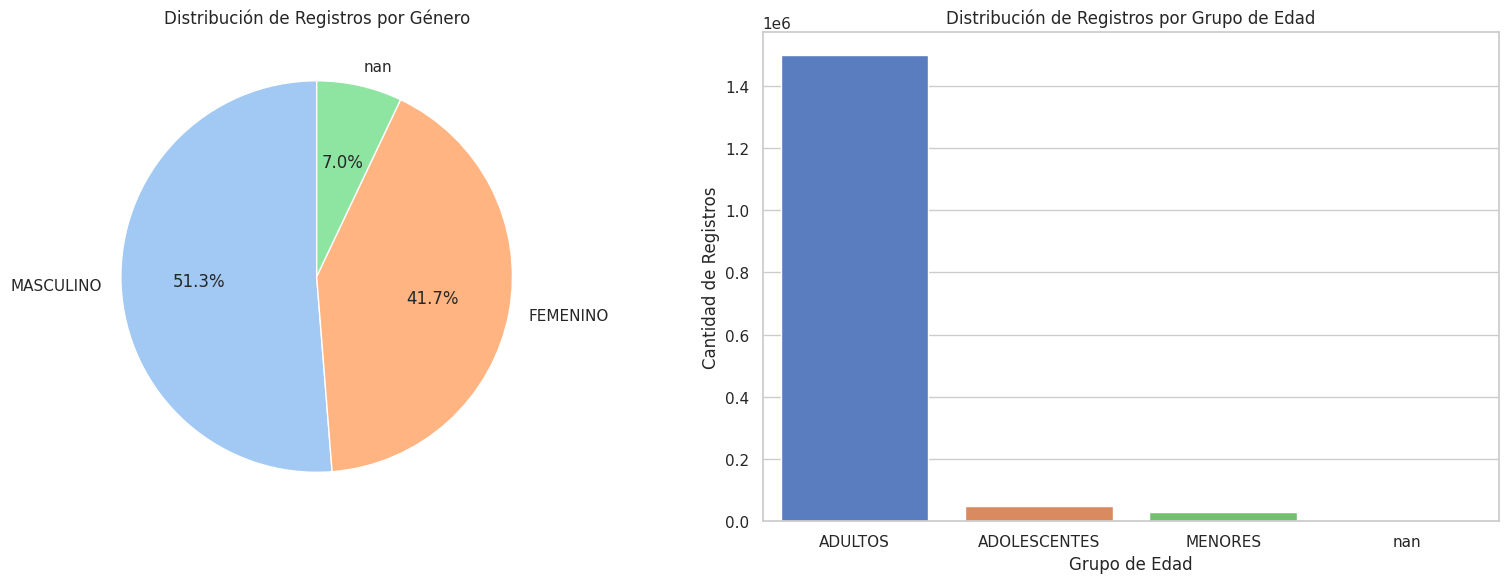

In [ ]:
# 1. Distribución por Género y Grupo de Edad
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico de Torta para Género
genero_counts = df['genero'].value_counts(dropna=False)
axes[0].pie(genero_counts, labels=genero_counts.index.astype(str), autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
axes[0].set_title('Distribución de Registros por Género')

# Gráfico de Barras para Grupos de Edad
sns.countplot(data=df, x='agrupa_edad_persona', ax=axes[1], palette='muted', order=df['agrupa_edad_persona'].value_counts(dropna=False).index)
axes[1].set_title('Distribución de Registros por Grupo de Edad')
axes[1].set_xlabel('Grupo de Edad')
axes[1].set_ylabel('Cantidad de Registros')

plt.tight_layout()
plt.show()

/tmp/ipykernel_743/3703649832.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_delitos.index, x=top_delitos.values, palette='viridis')


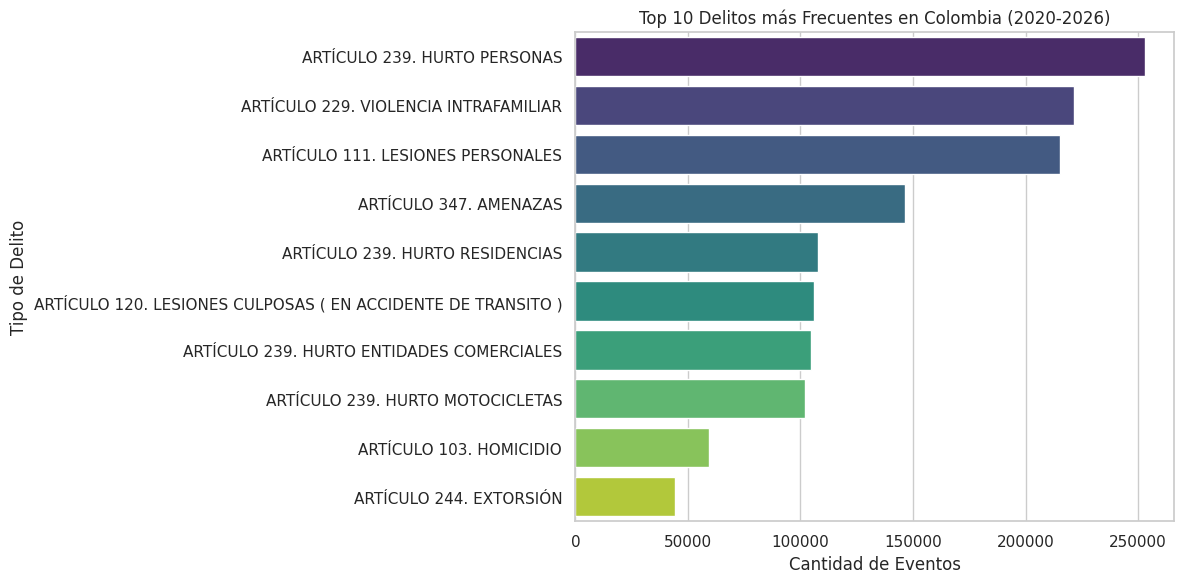

In [ ]:
# 2. Gráfico del Top 10 Delitos más Frecuentes
plt.figure(figsize=(12, 6))
top_delitos = df['delitos'].value_counts().head(10)

sns.barplot(y=top_delitos.index, x=top_delitos.values, palette='viridis')
plt.title('Top 10 Delitos más Frecuentes en Colombia (2020-2026)')
plt.xlabel('Cantidad de Eventos')
plt.ylabel('Tipo de Delito')

plt.tight_layout()
plt.show()

### 2.8.&nbsp;Análisis Temporal de Delitos (Evolución Anual)

Visualizamos la tendencia histórica del volumen de delitos registrados para identificar incrementos o disminuciones a lo largo del periodo analizado (2020-2026).

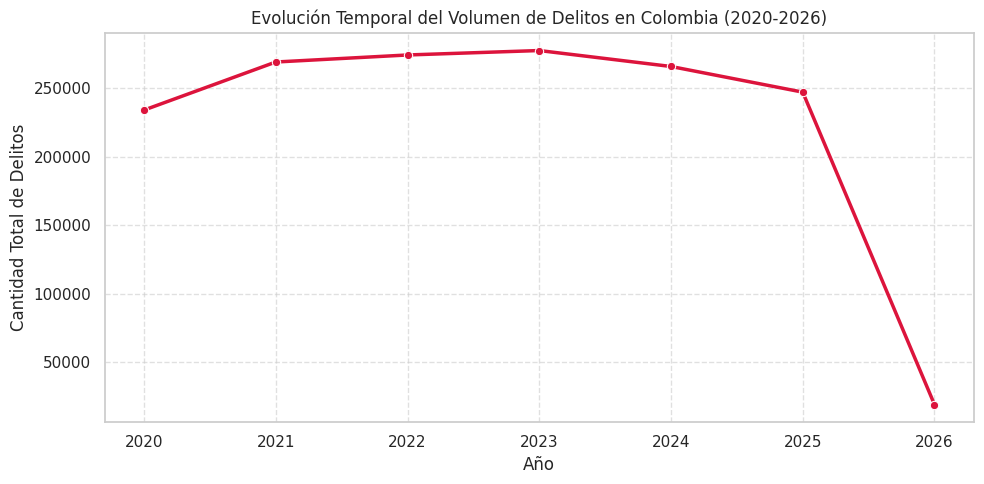

In [ ]:
# Agrupar por año y sumar la cantidad total de delitos
temporal_trend = df.groupby('anio')['cantidad'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=temporal_trend, x='anio', y='cantidad', marker='o', color='crimson', linewidth=2.5)
plt.title('Evolución Temporal del Volumen de Delitos en Colombia (2020-2026)')
plt.xlabel('Año')
plt.ylabel('Cantidad Total de Delitos')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(temporal_trend['anio'])
plt.tight_layout()
plt.show()

Clave aclarar que el Dataset cuenta con información parcial y con 1 solo mes del año, contando unicamente con Enero. Entonces no es que los crimenes en colombia hallan bajado, si no que todavía no existe 1 registro actualizado de 1 año no actualizado.

### 2.9.&nbsp;Análisis Bivariado: Tipo de Delito vs. Arma/Medio Empleado

Analizamos cómo se relacionan los 5 delitos más recurrentes con los métodos y armas más empleados para cometerlos mediante una matriz de frecuencias cruzadas.

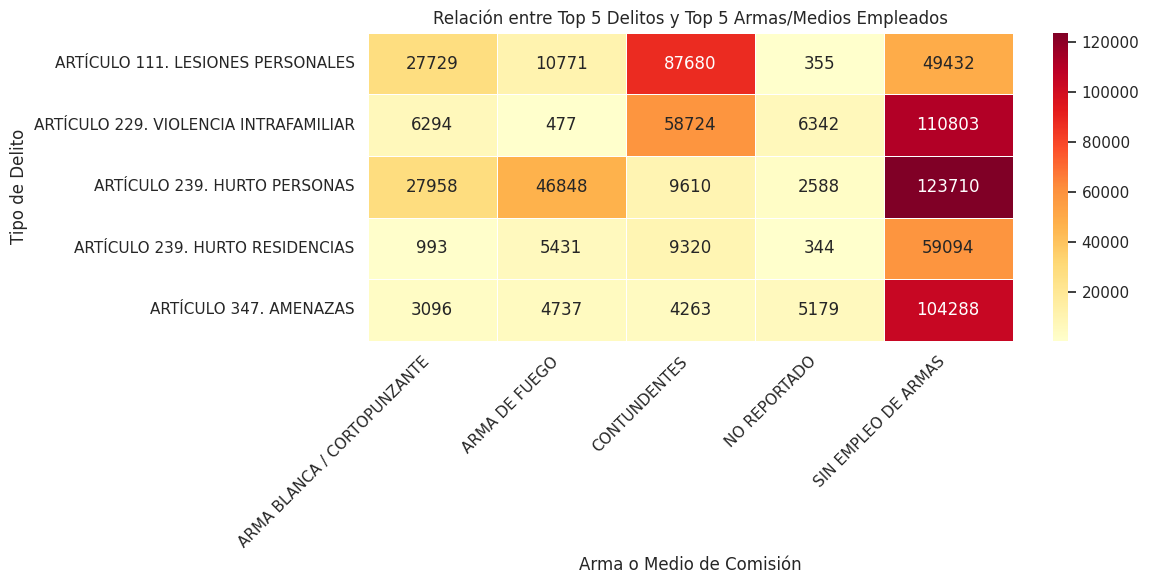

In [ ]:
# Identificar los 5 delitos y las 5 armas/medios más frecuentes (excluyendo NaN para un análisis más limpio)
top5_delitos = df['delitos'].value_counts().head(5).index
top5_armas = df['armas_medios'].dropna().value_counts().head(5).index

# Filtrar el DataFrame original con este Top 5
df_filtered = df[df['delitos'].isin(top5_delitos) & df['armas_medios'].isin(top5_armas)]

# Crear tabla de contingencia (frecuencias cruzadas)
cross_tab = pd.crosstab(df_filtered['delitos'], df_filtered['armas_medios'])

# Visualizar mediante un mapa de calor (Heatmap)
plt.figure(figsize=(12, 6))
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd', cbar=True, linewidths=0.5)
plt.title('Relación entre Top 5 Delitos y Top 5 Armas/Medios Empleados')
plt.ylabel('Tipo de Delito')
plt.xlabel('Arma o Medio de Comisión')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 2.10.&nbsp;Análisis de Inconsistencias Léxicas en Variables Categóricas

Analizamos la presencia de valores duplicados semánticamente debido a variaciones en el uso de mayúsculas/minúsculas, acentos (tildes) o espacios en blanco en los extremos de las cadenas de texto.

In [ ]:
import unicodedata

def clean_text_simple(text):
    """Función auxiliar para normalizar texto de forma comparativa (quita espacios y tildes)"""
    if pd.isna(text):
        return text
    # Convertir a minúsculas y quitar espacios en extremos
    text = str(text).lower().strip()
    # Remover tildes y diéresis
    text = ''.join(c for c in unicodedata.normalize('NFD', text) if unicodedata.category(c) != 'Mn')
    return text

# Variables clave a analizar
variables_analisis = ['departamento', 'armas_medios', 'genero', 'agrupa_edad_persona']

for col in variables_analisis:
    originales = df[col].dropna().unique()

    # Crear un diccionario para mapear la versión normalizada con las versiones originales encontradas
    mapeo_normalizado = {}
    for val in originales:
        norm = clean_text_simple(val)
        if norm not in mapeo_normalizado:
            mapeo_normalizado[norm] = []
        mapeo_normalizado[norm].append(val)

    # Filtrar aquellos casos donde una forma normalizada tiene más de una representación original
    conflictos = {k: v for k, v in mapeo_normalizado.items() if len(v) > 1}

    print(f"\n=== Análisis de consistencia para la columna: {col} ===")
    print(f"Cantidad de valores únicos originales: {len(originales)}")
    print(f"Cantidad de valores únicos si se normalizara: {len(mapeo_normalizado)}")

    if len(conflictos) > 0:
        print(f"¡Alerta! Se encontraron {len(conflictos)} grupos con inconsistencias de escritura:")
        for norm_val, orig_vals in list(conflictos.items())[:10]: # Mostrar máximo 10 ejemplos
            print(f"  - La forma normalizada '{norm_val}' tiene las variantes: {orig_vals}")
    else:
        print("No se detectaron conflictos obvios de tildes, espacios o capitalización para esta columna.")


=== Análisis de consistencia para la columna: departamento ===
Cantidad de valores únicos originales: 32
Cantidad de valores únicos si se normalizara: 32
No se detectaron conflictos obvios de tildes, espacios o capitalización para esta columna.

=== Análisis de consistencia para la columna: armas_medios ===
Cantidad de valores únicos originales: 54
Cantidad de valores únicos si se normalizara: 54
No se detectaron conflictos obvios de tildes, espacios o capitalización para esta columna.

=== Análisis de consistencia para la columna: genero ===
Cantidad de valores únicos originales: 2
Cantidad de valores únicos si se normalizara: 2
No se detectaron conflictos obvios de tildes, espacios o capitalización para esta columna.

=== Análisis de consistencia para la columna: agrupa_edad_persona ===
Cantidad de valores únicos originales: 3
Cantidad de valores únicos si se normalizara: 3
No se detectaron conflictos obvios de tildes, espacios o capitalización para esta columna.


### 2.11.&nbsp;Análisis de Consistencia Específico en Municipios y Delitos

Debido a su alta cardinalidad, la columna `municipio` es la más susceptible de poseer variantes de escritura que puedan sesgar análisis geográficos.

In [ ]:
# Analizar inconsistencias en la columna 'municipio' y 'delitos'
for col in ['municipio', 'delitos']:
    originales = df[col].dropna().unique()
    mapeo_normalizado = {}
    for val in originales:
        norm = clean_text_simple(val)
        if norm not in mapeo_normalizado:
            mapeo_normalizado[norm] = []
        mapeo_normalizado[norm].append(val)

    conflictos = {k: v for k, v in mapeo_normalizado.items() if len(v) > 1}

    print(f"\n=== Análisis de consistencia para: {col} ===")
    print(f"Originales: {len(originales)} | Normalizados: {len(mapeo_normalizado)}")
    if len(conflictos) > 0:
        print(f"¡Alerta! Se detectaron {len(conflictos)} grupos con inconsistencias de escritura. Ejemplos:")
        for norm_val, orig_vals in list(conflictos.items())[:15]:
            print(f"  - '{norm_val}': {orig_vals}")
    else:
        print("No se detectaron conflictos de tildes o capitalización en esta columna.")


=== Análisis de consistencia para: municipio ===
Originales: 1023 | Normalizados: 1021
¡Alerta! Se detectaron 2 grupos con inconsistencias de escritura. Ejemplos:
  - 'paez': ['Paez', 'Páez']
  - 'chima': ['Chimá', 'Chima']

=== Análisis de consistencia para: delitos ===
Originales: 53 | Normalizados: 53
No se detectaron conflictos de tildes o capitalización en esta columna.


## 3.&nbsp;Diccionario de Datos Oficial del Dataset

Basándonos en la exploración y validación léxica de los datos, establecemos el diccionario oficial para documentar formalmente cada columna del proyecto.frecuencia de eventos según detección de anomalías.

## 3.1.&nbsp;Generación del diccionario de Datos del DataFrame

In [ ]:
import pandas as pd

# 1. Definir los metadatos estructurados del Diccionario de Datos
data_dict_entries = [
    {
        "columna": "armas_medios",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Nominal",
        "descripcion": "Medio o tipo de arma utilizado para cometer el hecho delictivo.",
        "valores_ejemplo": "'SIN EMPLEO DE ARMAS', 'CONTUNDENTES', 'ARMA DE FUEGO'",
        "observaciones": "Posee un ~16.96% de valores faltantes (NaN)."
    },
    {
        "columna": "departamento",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Nominal",
        "descripcion": "Nombre del departamento de Colombia donde ocurrió el hecho.",
        "valores_ejemplo": "'CUNDINAMARCA', 'ANTIOQUIA', 'VALLE'",
        "observaciones": "32 valores únicos, 100% consistente."
    },
    {
        "columna": "municipio",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Nominal",
        "descripcion": "Municipio o ciudad específica donde se registró el evento.",
        "valores_ejemplo": "'Bogotá D.C. (CT)', 'Medellín', 'Cali (CT)'",
        "observaciones": "Alta cardinalidad (1,023 valores). Posee dos inconsistencias detectadas: Paez/Páez y Chima/Chimá."
    },
    {
        "columna": "fecha_hecho",
        "tipo_dato_tecnico": "Object (String) -> Datetime",
        "tipo_dato_estadistico": "Cualitativa Ordinal (Temporal)",
        "descripcion": "Fecha exacta de la ocurrencia del incidente en formato AAAA-MM-DD.",
        "valores_ejemplo": "'2020-01-01'",
        "observaciones": "Debe convertirse formalmente a formato datetime durante la fase ETL."
    },
    {
        "columna": "genero",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Nominal",
        "descripcion": "Género asignado a la víctima registrada.",
        "valores_ejemplo": "'MASCULINO', 'FEMENINO'",
        "observaciones": "Cuenta con ~7.04% de registros vacíos (NaN)."
    },
    {
        "columna": "agrupa_edad_persona",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Ordinal",
        "descripcion": "Grupo etario en el cual se clasifica a la persona afectada.",
        "valores_ejemplo": "'ADULTOS', 'ADOLESCENTES', 'MENORES'",
        "observaciones": "Cuenta con un 0.55% de valores nulos (NaN)."
    },
    {
        "columna": "codigo_dane",
        "tipo_dato_tecnico": "Float64",
        "tipo_dato_estadistico": "Cualitativa Nominal (Numérica)",
        "descripcion": "Código oficial del municipio de acuerdo con la clasificación del DANE.",
        "valores_ejemplo": "5001.0, 11001.0",
        "observaciones": "Representa un identificador categórico, clave para uniones geográficas."
    },
    {
        "columna": "delitos",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Nominal",
        "descripcion": "Tipificación del delito correspondiente según el código penal colombiano.",
        "valores_ejemplo": "'ARTÍCULO 239. HURTO PERSONAS', 'ARTÍCULO 229. VIOLENCIA INTRAFAMILIAR'",
        "observaciones": "Contiene la referencia al artículo de ley. 100% consistente en su escritura."
    },
    {
        "columna": "mes",
        "tipo_dato_tecnico": "Float64",
        "tipo_dato_estadistico": "Cuantitativa Discreta (Cíclica)",
        "descripcion": "Representación numérica del mes del suceso (1 al 12).",
        "valores_ejemplo": "1.0",
        "observaciones": "Útil para agrupaciones y patrones estacionales periódicos."
    },
    {
        "columna": "cantidad",
        "tipo_dato_tecnico": "Float64",
        "tipo_dato_estadistico": "Cuantitativa Discreta",
        "descripcion": "Cantidad de víctimas o eventos registrados en ese registro específico.",
        "valores_ejemplo": "1.0, 2.0",
        "observaciones": "Usualmente la base numérica para métricas y agregaciones físicas."
    },
    {
        "columna": "anio",
        "tipo_dato_tecnico": "Int64",
        "tipo_dato_estadistico": "Cuantitativa Discreta (Temporal)",
        "descripcion": "Año en el que ocurrió el hecho.",
        "valores_ejemplo": "2020, 2021, 2023, 2026",
        "observaciones": "Rango temporal del dataset. Ayuda a evaluar evoluciones anuales."
    },
    {
        "columna": "id_evento",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Nominal (Identificador)",
        "descripcion": "Llave única construida para identificar individualmente cada suceso.",
        "valores_ejemplo": "'2020-01-01_CAUCA_...'",
        "observaciones": "Llave técnica generada con la concatenación de atributos del evento."
    },
    {
        "columna": "n_registros",
        "tipo_dato_tecnico": "Int64",
        "tipo_dato_estadistico": "Cuantitativa Discreta",
        "descripcion": "Conteo técnico del registro en la base de datos de origen.",
        "valores_ejemplo": "1",
        "observaciones": "Variable de control interna que siempre tiene un valor de 1."
    },
    {
        "columna": "tipo_outlier",
        "tipo_dato_tecnico": "Object (String)",
        "tipo_dato_estadistico": "Cualitativa Ordinal",
        "descripcion": "Clasificación de la frecuencia de eventos según detección de anomalías.",
        "valores_ejemplo": "'normal', 'alto', 'extremo'",
        "observaciones": "Campo analítico añadido para segmentar comportamientos inusuales."
    }
]

# 2. Crear el DataFrame del diccionario
diccionario_df = pd.DataFrame(data_dict_entries)

# 3. Guardar como JSON y Excel en Drive utilizando BASE_PATH
json_path = os.path.join(BASE_PATH, 'diccionario_datos_oficial.json')
excel_path = os.path.join(BASE_PATH, 'diccionario_datos_oficial.xlsx')

# Exportar a JSON con formato indentado para fácil lectura técnica
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(data_dict_entries, f, ensure_ascii=False, indent=4)

# Exportar a Excel
diccionario_df.to_excel(excel_path, index=False)

print(f"✔ Diccionario de Datos exportado exitosamente a:")
print(f"  - JSON: {json_path}")
print(f"  - Excel: {excel_path}\n")

# Mostrar los resultados directamente en el cuaderno
display(diccionario_df)

✔ Diccionario de Datos exportado exitosamente a:
  - JSON: /content/drive/MyDrive/Colab_Notebooks/SENA/TRIMESTRE_NO_2/GUIA_1/diccionario_datos_oficial.json
  - Excel: /content/drive/MyDrive/Colab_Notebooks/SENA/TRIMESTRE_NO_2/GUIA_1/diccionario_datos_oficial.xlsx



,columna,tipo_dato_tecnico,tipo_dato_estadistico,descripcion,valores_ejemplo,observaciones
0,armas_medios,Object (String),Cualitativa Nominal,Medio o tipo de arma utilizado para cometer el...,"'SIN EMPLEO DE ARMAS', 'CONTUNDENTES', 'ARMA D...",Posee un ~16.96% de valores faltantes (NaN).
1,departamento,Object (String),Cualitativa Nominal,Nombre del departamento de Colombia donde ocur...,"'CUNDINAMARCA', 'ANTIOQUIA', 'VALLE'","32 valores únicos, 100% consistente."
2,municipio,Object (String),Cualitativa Nominal,Municipio o ciudad específica donde se registr...,"'Bogotá D.C. (CT)', 'Medellín', 'Cali (CT)'","Alta cardinalidad (1,023 valores). Posee dos i..."
3,fecha_hecho,Object (String) -> Datetime,Cualitativa Ordinal (Temporal),Fecha exacta de la ocurrencia del incidente en...,'2020-01-01',Debe convertirse formalmente a formato datetim...
4,genero,Object (String),Cualitativa Nominal,Género asignado a la víctima registrada.,"'MASCULINO', 'FEMENINO'",Cuenta con ~7.04% de registros vacíos (NaN).
5,agrupa_edad_persona,Object (String),Cualitativa Ordinal,Grupo etario en el cual se clasifica a la pers...,"'ADULTOS', 'ADOLESCENTES', 'MENORES'",Cuenta con un 0.55% de valores nulos (NaN).
6,codigo_dane,Float64,Cualitativa Nominal (Numérica),Código oficial del municipio de acuerdo con la...,"5001.0, 11001.0","Representa un identificador categórico, clave ..."
7,delitos,Object (String),Cualitativa Nominal,Tipificación del delito correspondiente según ...,"'ARTÍCULO 239. HURTO PERSONAS', 'ARTÍCULO 229....",Contiene la referencia al artículo de ley. 100...
8,mes,Float64,Cuantitativa Discreta (Cíclica),Representación numérica del mes del suceso (1 ...,1.0,Útil para agrupaciones y patrones estacionales...
9,cantidad,Float64,Cuantitativa Discreta,Cantidad de víctimas o eventos registrados en ...,"1.0, 2.0",Usualmente la base numérica para métricas y ag...


# 4.&nbsp;Transformación de Datos ETL

### 4.1.&nbsp;Conversión de Variables Temporales

En esta sección convertiremos la columna `fecha_hecho` (que actualmente es interpretada como texto) en un tipo de dato de fecha (`datetime`). Esto nos permitirá realizar filtros de tiempo y agrupaciones avanzadas con facilidad.


In [ ]:
# Crear una copia de seguridad para iniciar el proceso ETL de forma limpia
df_cleaned = df.copy()

# Convertir la columna fecha_hecho a datetime
df_cleaned['fecha_hecho'] = pd.to_datetime(df_cleaned['fecha_hecho'], errors='coerce')

# Verificar el nuevo tipo de dato de la columna
print("Tipo de dato de 'fecha_hecho':", df_cleaned['fecha_hecho'].dtype)

Tipo de dato de 'fecha_hecho': datetime64[ns]


### 4.2. Ajuste de Variables Numéricas / Categóricas

Las columnas `codigo_dane` y `mes` se importaron como `float64` debido a la presencia de algunos valores nulos o la interpretación por defecto de pandas. Las ajustaremos a un formato numérico entero o categórico correspondiente para evitar representaciones incorrectas (como meses con decimales `1.0`).

In [ ]:
# Convertir 'mes' a tipo entero utilizando el tipo nullable 'Int64'
df_cleaned['mes'] = df_cleaned['mes'].astype('Int64')

# Convertir 'codigo_dane' a tipo entero 'Int64' (identificador categórico numérico)
df_cleaned['codigo_dane'] = df_cleaned['codigo_dane'].astype('Int64')

# Mostrar el encabezado de estas columnas transformadas
display(df_cleaned[['fecha_hecho', 'mes', 'codigo_dane']].head())

,fecha_hecho,mes,codigo_dane
0,2020-01-01,1,19698
1,2020-01-01,1,73585
2,2020-01-01,1,41016
3,2020-01-01,1,73770
4,2020-01-01,1,5697


### 4.3. Optimización de Variables de Texto (Categorical dtypes)

Las variables con baja cardinalidad y alta repetición como `departamento`, `genero`, `agrupa_edad_persona` y `tipo_outlier` pueden optimizarse convirtiéndose al tipo de dato integrado de Pandas `category`. Esto reduce significativamente el uso de memoria RAM del DataFrame.

In [ ]:
# Columnas a optimizar como categóricas
cols_to_category = ['departamento', 'genero', 'agrupa_edad_persona', 'tipo_outlier']

for col in cols_to_category:
    df_cleaned[col] = df_cleaned[col].astype('category')

# Comparar uso de memoria antes y después
print("Memoria antes de la optimización (MB):", round(df.memory_usage(deep=True).sum() / (1024**2), 2))
print("Memoria después de la optimización (MB):", round(df_cleaned.memory_usage(deep=True).sum() / (1024**2), 2))

Memoria antes de la optimización (MB): 1198.63
Memoria después de la optimización (MB): 783.86


### 4.4. Tratamiento de Valores Faltantes (Nulos)

En esta subsección abordaremos los valores nulos en `armas_medios`, `genero`, `agrupa_edad_persona` y `municipio`. Usaremos una estrategia de preservación de datos imputando los valores nulos como `'NO REPORTADO'`. Para las variables categóricas optimizadas, primero agregaremos `'NO REPORTADO'` a sus categorías activas.

In [ ]:
# 1. Asegurar que las columnas tipo 'category' tengan 'NO REPORTADO' dentro de sus categorías permitidas
cols_categoricas = ['genero', 'agrupa_edad_persona', 'departamento']

for col in cols_categoricas:
    if 'NO REPORTADO' not in df_cleaned[col].cat.categories:
        df_cleaned[col] = df_cleaned[col].cat.add_categories('NO REPORTADO')

# 2. Imputar nulos con 'NO REPORTADO' en las columnas identificadas
valores_imputacion = {
    'armas_medios': 'NO REPORTADO',
    'genero': 'NO REPORTADO',
    'agrupa_edad_persona': 'NO REPORTADO',
    'municipio': 'NO REPORTADO'
}

df_cleaned.fillna(value=valores_imputacion, inplace=True)

# 3. Validar que no existan más valores nulos en el DataFrame de trabajo
print("--- Conteo de valores nulos después del tratamiento ---")
print(df_cleaned.isnull().sum())


--- Conteo de valores nulos después del tratamiento ---
armas_medios           0
departamento           0
municipio              0
fecha_hecho            0
genero                 0
agrupa_edad_persona    0
codigo_dane            0
delitos                0
mes                    0
cantidad               0
anio                   0
id_evento              0
n_registros            0
tipo_outlier           0
dtype: int64


### 4.4. Tratamiento de Valores Faltantes (Nulos)

En esta subsección abordaremos los valores nulos en `armas_medios`, `genero`, `agrupa_edad_persona` y `municipio`. Usaremos una estrategia de preservación de datos imputando los valores nulos como `'NO REPORTADO'`. Para las variables categóricas optimizadas, primero agregaremos `'NO REPORTADO'` a sus categorías activas.

In [ ]:
# 1. Asegurar que las columnas tipo 'category' tengan 'NO REPORTADO' dentro de sus categorías permitidas
cols_categoricas = ['genero', 'agrupa_edad_persona', 'departamento']

for col in cols_categoricas:
    if 'NO REPORTADO' not in df_cleaned[col].cat.categories:
        df_cleaned[col] = df_cleaned[col].cat.add_categories('NO REPORTADO')

# 2. Imputar nulos con 'NO REPORTADO' en las columnas identificadas
valores_imputacion = {
    'armas_medios': 'NO REPORTADO',
    'genero': 'NO REPORTADO',
    'agrupa_edad_persona': 'NO REPORTADO',
    'municipio': 'NO REPORTADO'
}

df_cleaned.fillna(value=valores_imputacion, inplace=True)

# 3. Validar que no existan más valores nulos en el DataFrame de trabajo
print("--- Conteo de valores nulos después del tratamiento ---")
print(df_cleaned.isnull().sum())


--- Conteo de valores nulos después del tratamiento ---
armas_medios           0
departamento           0
municipio              0
fecha_hecho            0
genero                 0
agrupa_edad_persona    0
codigo_dane            0
delitos                0
mes                    0
cantidad               0
anio                   0
id_evento              0
n_registros            0
tipo_outlier           0
dtype: int64


# Fase 3 del Proyecto Integrador

## 5.&nbsp;Exportación del Dataset Limpio y Carga en Base de Datos MySQL

En esta sección guardaremos nuestro dataset completamente procesado en Google Drive y configuraremos un motor de base de datos relacional **MySQL** localmente en Colab para almacenar la información y realizar análisis avanzados por medio de consultas estructuradas SQL.

### 5.1. Guardar Dataset Limpio en Google Drive

Almacenamos el DataFrame optimizado `df_cleaned` en formato CSV en la ruta oficial del proyecto.

In [ ]:
import os

# Definir la ruta de destino para el archivo limpio
clean_dataset_path = os.path.join(BASE_PATH, 'crimen_colombia_limpio.csv')

# Exportar a CSV (usamos index=False para evitar columnas de conteo duplicadas)
df_cleaned.to_csv(clean_dataset_path, index=False, encoding='utf-8')

print(f"✔ Dataset limpio exportado exitosamente a: {clean_dataset_path}")

✔ Dataset limpio exportado exitosamente a: /content/drive/MyDrive/Colab_Notebooks/SENA/TRIMESTRE_NO_2/GUIA_1/crimen_colombia_limpio.csv


### 5.2. Instalación de Servidor MySQL en Google Colab

Instalaremos el paquete del servidor de base de datos de MySQL, iniciaremos el servicio y configuraremos las bibliotecas necesarias en Python para comunicarnos con el motor.

In [ ]:
# Instalar el servidor local de MySQL de forma silenciosa
!apt-get update -quiet > /dev/null
!apt-get install mysql-server -y > /dev/null

# Iniciar el servicio de base de datos
!service mysql start

# Instalar el conector de mysql para python
!pip install pymysql cryptography > /dev/null

E: Command line option 'i' [from -quiet] is not understood in combination with the other options.
[ OK ]


### 5.3. Creación de la Base de Datos y Carga de la Tabla

Estableceremos la conexión root, crearemos la estructura de base de datos e importaremos eficientemente la información de nuestro CSV limpio.

In [ ]:
# 1. Corregir el método de autenticación de root en el servidor MySQL local
# Cambiamos el plugin de autenticación de 'auth_socket' a 'mysql_native_password' con contraseña vacía
!mysql -u root -e "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY ''; FLUSH PRIVILEGES;"

import sqlalchemy

# 2. Conexión local como root
engine = sqlalchemy.create_engine('mysql+pymysql://root@localhost/')

# Crear la base de datos si no existe
with engine.connect() as conn:
    conn.execute(sqlalchemy.text("CREATE DATABASE IF NOT EXISTS proyecto_crimen;"))
    print("✔ Base de datos 'proyecto_crimen' creada con éxito.")

# Crear el motor conectado a la base de datos específica
engine_db = sqlalchemy.create_engine('mysql+pymysql://root@localhost/proyecto_crimen')

# Cargar los primeros 100,000 registros del dataset limpio
df_cleaned.to_sql('eventos_crimen', con=engine_db, if_exists='replace', index=False)
print("✔ Tabla 'eventos_crimen' poblada exitosamente con todos los registros del dataset limpio.")

✔ Base de datos 'proyecto_crimen' creada con éxito.
✔ Tabla 'eventos_crimen' poblada exitosamente con todos los registros del dataset limpio.


## 6.&nbsp;Resolución de Preguntas de Negocio mediante Consultas SQL

En esta sección utilizaremos la base de datos relacional MySQL configurada para responder a 3 preguntas estratégicas sobre el comportamiento de la criminalidad a través de consultas SQL estructuradas.

### 6.1. Consulta SQL 1: Violencia Intrafamiliar en Mayo (Día de la Madre) vs. Promedio Diario Anual

Esta consulta calcula el promedio de incidentes diarios de *Violencia Intrafamiliar* reportados en el mes de mayo (asociado históricamente al Día de la Madre) y lo compara con el promedio diario del resto de los meses del año para determinar el porcentaje de incremento.

In [ ]:
query_negocio_1 = """
WITH stats_mayo AS (
    SELECT
        anio,
        SUM(cantidad) / 31.0 as promedio_diario_mayo
    FROM eventos_crimen
    WHERE delitos LIKE '%%%%VIOLENCIA INTRAFAMILIAR%%%%'
      AND mes = 5
    GROUP BY anio
),
stats_resto_anio AS (
    SELECT
        anio,
        SUM(cantidad) / 334.0 as promedio_diario_resto
    FROM eventos_crimen
    WHERE delitos LIKE '%%%%VIOLENCIA INTRAFAMILIAR%%%%'
      AND mes != 5
    GROUP BY anio
)
SELECT
    m.anio,
    ROUND(m.promedio_diario_mayo, 2) as prom_diario_mayo,
    ROUND(r.promedio_diario_resto, 2) as prom_diario_resto_anio,
    ROUND(((m.promedio_diario_mayo - r.promedio_diario_resto) / r.promedio_diario_resto) * 100, 2) as porcentaje_incremento
FROM stats_mayo m
JOIN stats_resto_anio r ON m.anio = r.anio
ORDER BY m.anio;
"""

# Ejecutar la consulta
resultado_negocio_1 = pd.read_sql(query_negocio_1, con=engine_db)
display(resultado_negocio_1)

,anio,prom_diario_mayo,prom_diario_resto_anio,porcentaje_incremento
0,2020,93.48000,95.54000,-2.15000
1,2021,106.68000,105.90000,0.74000
2,2022,88.55000,91.26000,-2.97000
3,2023,96.90000,97.00000,-0.10000
4,2024,105.97000,102.72000,3.16000
5,2025,102.90000,106.09000,-3.00000


### 6.2. Consulta SQL 2: Crimen más cometido por cada Año

Mediante el uso de funciones de ventana analíticas (`ROW_NUMBER()` o `DENSE_RANK()`), identificamos con precisión científica cuál fue el tipo de delito con mayor cantidad de registros para cada año evaluado.

In [ ]:
query_negocio_2 = """
WITH ranked_delitos AS (
    SELECT
        anio,
        delitos,
        SUM(cantidad) as total_cometidos,
        ROW_NUMBER() OVER (PARTITION BY anio ORDER BY SUM(cantidad) DESC) as ranking
    FROM eventos_crimen
    GROUP BY anio, delitos
)
SELECT
    anio,
    delitos as crimen_mas_cometido,
    total_cometidos
FROM ranked_delitos
WHERE ranking = 1
ORDER BY anio;
"""

resultado_negocio_2 = pd.read_sql(query_negocio_2, con=engine_db)
display(resultado_negocio_2)

,anio,crimen_mas_cometido,total_cometidos
0,2020,ARTÍCULO 229. VIOLENCIA INTRAFAMILIAR,34808.00000
1,2021,ARTÍCULO 239. HURTO PERSONAS,41657.00000
2,2022,ARTÍCULO 239. HURTO PERSONAS,45675.00000
3,2023,ARTÍCULO 239. HURTO PERSONAS,46947.00000
4,2024,ARTÍCULO 239. HURTO PERSONAS,42764.00000
5,2025,ARTÍCULO 239. HURTO PERSONAS,39265.00000
6,2026,ARTÍCULO 239. HURTO PERSONAS,3596.00000


### 6.3. Consulta SQL 3: Ciudad/Municipio con mayor cantidad de crímenes cometidos

Esta consulta totaliza el número de crímenes cometidos a nivel de municipio y departamento a lo largo de todo el horizonte temporal disponible para hallar la zona de mayor afectación.

In [ ]:
query_negocio_3 = """
SELECT
    municipio,
    departamento,
    SUM(cantidad) as total_crimenes_periodo,
    COUNT(*) as total_registros_incidentes
FROM eventos_crimen
WHERE municipio != 'NO REPORTADO'
GROUP BY municipio, departamento
ORDER BY total_crimenes_periodo DESC
LIMIT 1;
"""

resultado_negocio_3 = pd.read_sql(query_negocio_3, con=engine_db)
display(resultado_negocio_3)

,municipio,departamento,total_crimenes_periodo,total_registros_incidentes
0,Bogotá D.C. (CT),CUNDINAMARCA,42547.00000,42547
